# Predicting Past-Due Rent at SLCM: Linear, Polynomial, Ridge, and Lasso Regression

The question I'm trying to answer: can household, income, employment, and housing information help predict how much past-due rent a household owes (`past_due_rent`)?

My plan is to explore the data, set up pipelines for the numeric and categorical columns, and then fit four models on the same train/test split (`random_state=42`). After that I'll compare how they behave and think about what the results mean for SLCM.

## 1. Setup and data loading

In [3]:
from pathlib import Path

FILE = "SLCM_rent_arrears_student_clean.csv"
# Fill in after you push to GitHub (use the "Raw" link for the CSV):
GITHUB_RAW = "https://raw.githubusercontent.com/<username>/<repo>/main/SLCM_rent_arrears_student_clean.csv"

if Path(FILE).exists():                      # 1) CSV is next to the notebook
    path = FILE
else:
    try:                                     # 2) Google Colab: pop up an upload box
        from google.colab import files
        uploaded = files.upload()
        path = next(iter(uploaded))          # use whatever name the upload has
    except ImportError:                      # 3) anywhere else: read from GitHub
        path = GITHUB_RAW

df = pd.read_csv(path)
print(path, df.shape)
df.head()

SLCM_rent_arrears_student_clean.csv (1754, 14)


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


## 2. Exploratory data analysis

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1754 entries, 0 to 1753
Data columns (total 14 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   record_id                   1754 non-null   object 
 1   adults_in_household         1754 non-null   int64  
 2   children_in_household       1754 non-null   int64  
 3   household_has_65plus        1754 non-null   object 
 4   monthly_household_income    1646 non-null   float64
 5   income_sources              1754 non-null   object 
 6   employment_status           1754 non-null   object 
 7   has_housing_voucher         1754 non-null   object 
 8   eviction_in_progress        1753 non-null   object 
 9   behind_on_utilities         1747 non-null   object 
 10  main_reason_behind_on_rent  1738 non-null   object 
 11  intake_quarter              1754 non-null   object 
 12  monthly_rent                1746 non-null   float64
 13  past_due_rent               1754 

In [5]:
print("Missing values per column:")
print(df.isna().sum()[df.isna().sum() > 0])
print("\nDuplicate rows:", df.duplicated().sum())
df[["adults_in_household","children_in_household","monthly_household_income","monthly_rent","past_due_rent"]].describe().T

Missing values per column:
monthly_household_income      108
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
monthly_rent                    8
dtype: int64

Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
adults_in_household,1754.0,1.385975,0.919366,0.0,1.0,1.0,2.00,6.0
children_in_household,1754.0,1.071266,1.269254,0.0,0.0,1.0,2.00,6.0
monthly_household_income,1646.0,1303.932439,1285.928291,0.0,0.0,1000.0,2000.00,10000.0
monthly_rent,1746.0,967.054750,451.094487,0.0,720.0,975.0,1200.75,4300.0
past_due_rent,1754.0,2408.006933,2089.515372,0.0,1050.0,2000.0,3200.00,20000.0


About 6% of households (108) are missing `monthly_household_income`, and a few rows are missing `monthly_rent`, `behind_on_utilities`, `main_reason_behind_on_rent`, or `eviction_in_progress`. I'll fill these in with imputers inside the pipeline so the fill values only come from the training data. `record_id` is just an ID, so I'm leaving it out of the features.

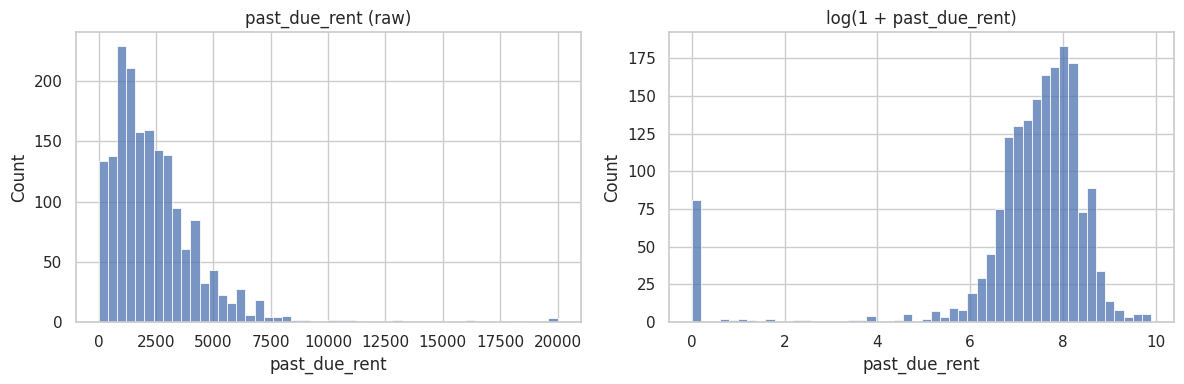

Skewness: 2.96
Rows with past_due_rent == 0: 81


In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["past_due_rent"], bins=50, ax=ax[0])
ax[0].set_title("past_due_rent (raw)")
sns.histplot(np.log1p(df["past_due_rent"]), bins=50, ax=ax[1])
ax[1].set_title("log(1 + past_due_rent)")
plt.tight_layout(); plt.show()
print("Skewness:", round(df["past_due_rent"].skew(), 2))
print("Rows with past_due_rent == 0:", (df["past_due_rent"] == 0).sum())

The target is right-skewed. Most households owe a few thousand dollars, but a few owe a lot more (the max is \$20,000). Since these models minimize squared error, those big values pull on the fit, so I expect the biggest misses to be the households with the highest balances. I kept the target in dollars (no log transform) so the errors are easy to read.

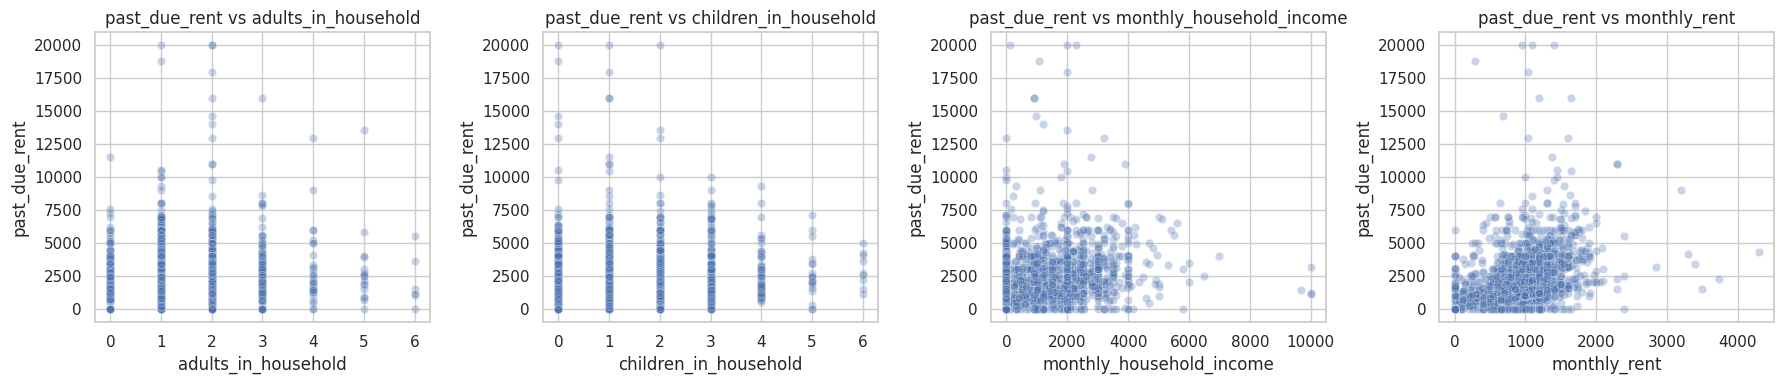

adults_in_household         0.086
children_in_household       0.101
monthly_household_income    0.165
monthly_rent                0.332
past_due_rent               1.000
Name: past_due_rent, dtype: float64


In [7]:
num_cols = ["adults_in_household","children_in_household","monthly_household_income","monthly_rent"]
fig, ax = plt.subplots(1, 4, figsize=(18, 4))
for a, c in zip(ax, num_cols):
    sns.scatterplot(data=df, x=c, y="past_due_rent", alpha=0.3, ax=a)
    a.set_title(f"past_due_rent vs {c}")
plt.tight_layout(); plt.show()

print(df[num_cols + ["past_due_rent"]].corr()["past_due_rent"].round(3))

The correlations with past-due rent are fairly weak. `monthly_rent` is the strongest at about 0.33, income is around 0.17, and household size is lower than that. A higher rent does mean more gets owed for each missed month, so that makes sense, but the scatterplots are really spread out at every rent level. I don't expect a high R² here.

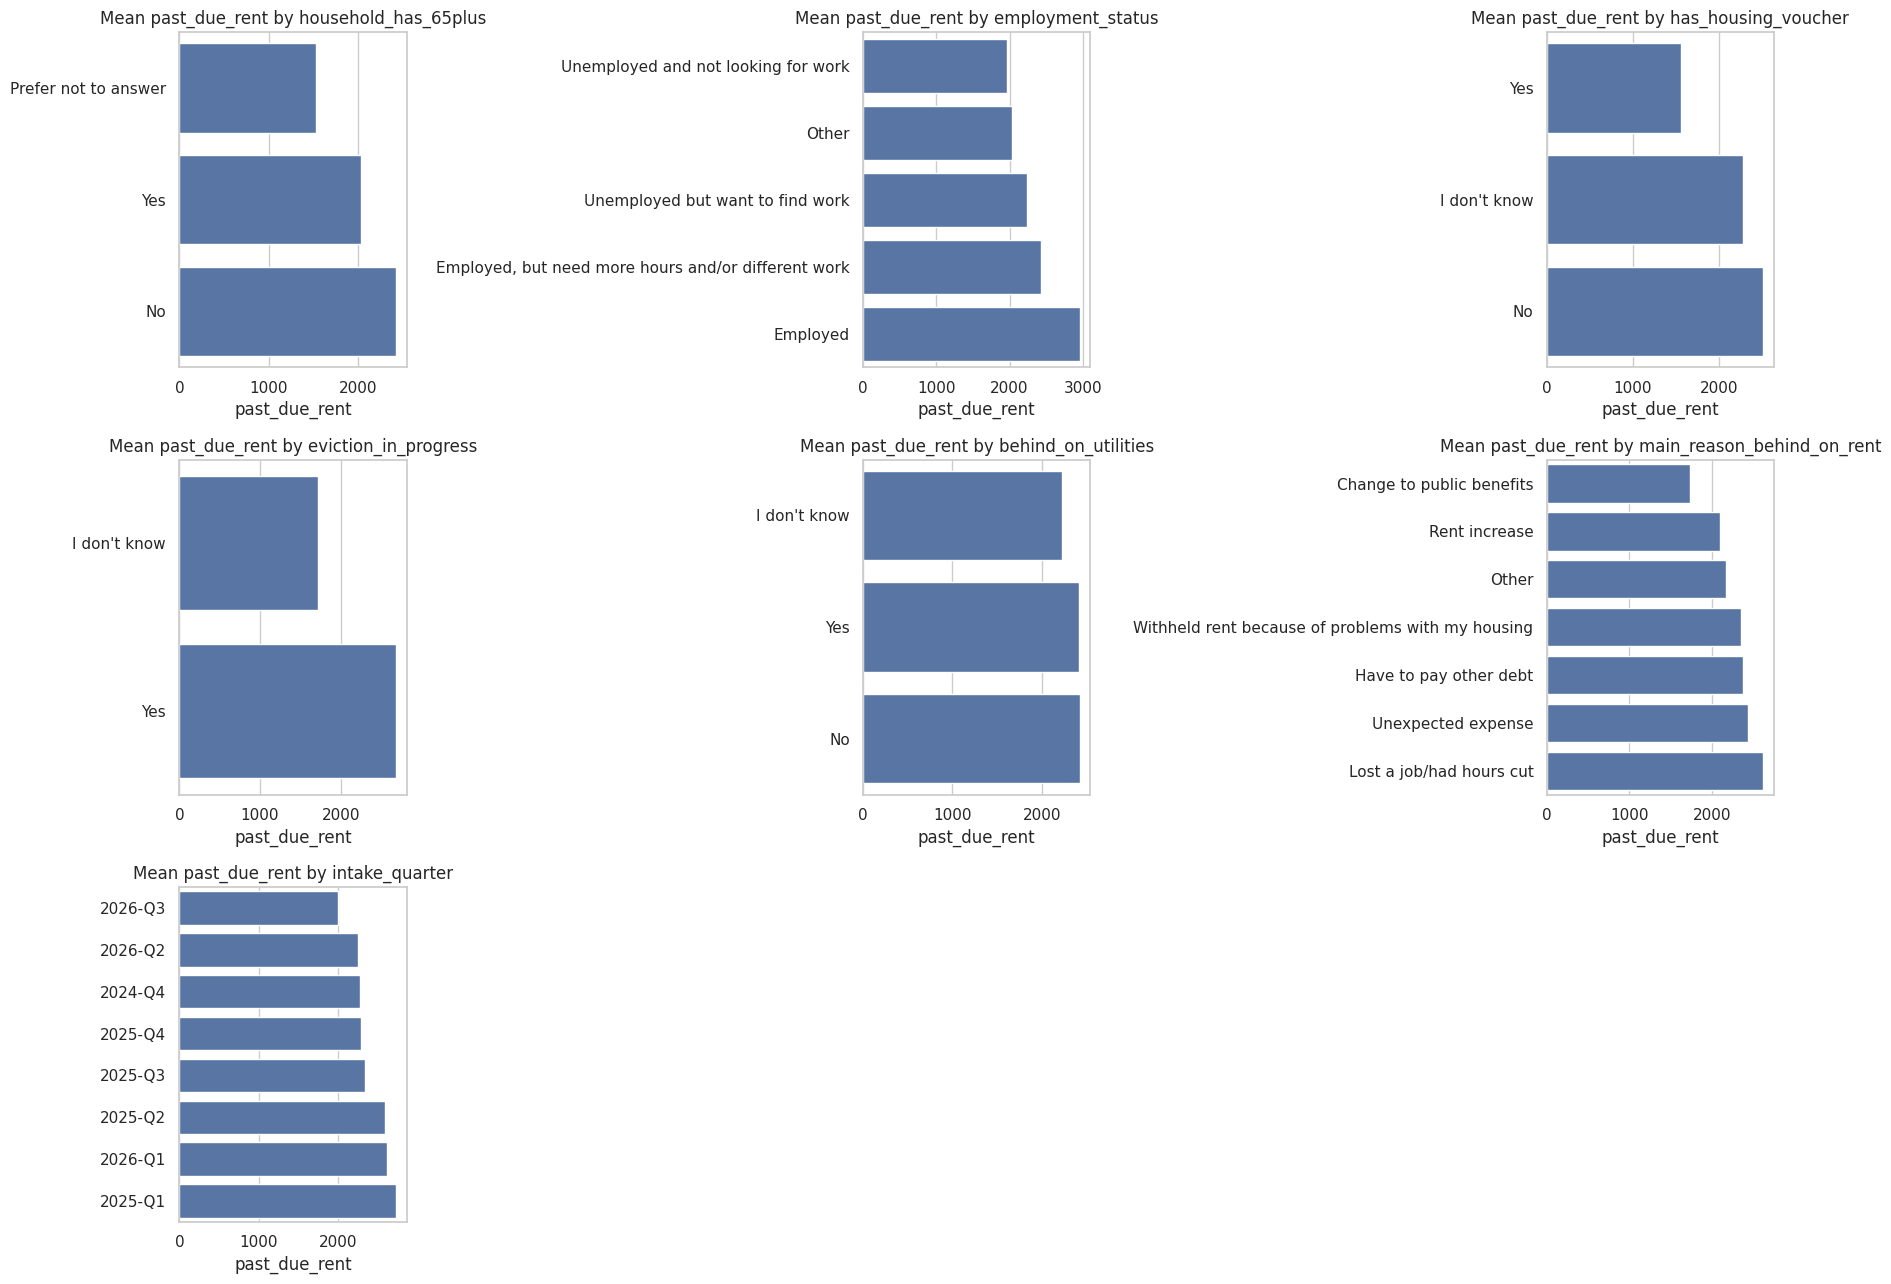

In [8]:
cat_cols_eda = ["household_has_65plus","employment_status","has_housing_voucher","eviction_in_progress",
                "behind_on_utilities","main_reason_behind_on_rent","intake_quarter"]
fig, axes = plt.subplots(3, 3, figsize=(18, 13))
for a, c in zip(axes.ravel(), cat_cols_eda):
    order = df.groupby(c)["past_due_rent"].mean().sort_values().index
    sns.barplot(data=df, y=c, x="past_due_rent", order=order, ax=a, errorbar=None)
    a.set_title(f"Mean past_due_rent by {c}"); a.set_ylabel("")
for a in axes.ravel()[len(cat_cols_eda):]: a.axis("off")
plt.tight_layout(); plt.show()

The averages do change a bit across groups (for example by `main_reason_behind_on_rent` and `intake_quarter`), but the differences are small compared to how spread out the target is. I think the categorical columns might add a little signal, but not much.

## 3. Feature preparation

`income_sources` has several answers packed into one text field (like `"Food benefits - TANF/SNAP, No income, Other"`). If I one-hot encoded it as is, I'd get 87 categories and most of them would only have a few households. So I split it into one 0/1 column for each income source. It's a simple row-by-row rule that doesn't learn anything from the data, so doing it before the train/test split doesn't cause leakage.

In [9]:
sources = ["Full-time employment","Part-time employment","No income","Food benefits - TANF/SNAP",
           "Social Security - SSI/SSDI","Child support","Unemployment benefits","Other"]

def has_source(s, src):
    return int(src in [x.strip() for x in s.split(",")]) if isinstance(s, str) else 0

for s in sources:
    df["src_" + s] = df["income_sources"].apply(lambda v: has_source(v, s))

print(df[[c for c in df if c.startswith("src_")]].sum())

src_Full-time employment          552
src_Part-time employment          298
src_No income                     533
src_Food benefits - TANF/SNAP     515
src_Social Security - SSI/SSDI    375
src_Child support                  81
src_Unemployment benefits          22
src_Other                         114
dtype: int64


In [10]:
target = "past_due_rent"
X = df.drop(columns=["record_id", target, "income_sources"])
y = df[target]

numeric_features = ["adults_in_household","children_in_household","monthly_household_income","monthly_rent"]
flag_features = [c for c in X.columns if c.startswith("src_")]
categorical_features = [c for c in X.columns if c not in numeric_features + flag_features]

print("Numeric:    ", numeric_features)
print("Categorical:", categorical_features)
print("Indicators: ", len(flag_features), "income-source flags")

Numeric:     ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical: ['household_has_65plus', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']
Indicators:  8 income-source flags


## 4. Train/test split

I made one 80/20 split (`random_state=42`) and used it for all four models. That way any difference in performance comes from the models and not from the data they saw.

In [11]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1403, 19)  Test: (351, 19)


## 5. Preprocessing pipelines

- **Numeric columns:** median imputation, then polynomial features (only for the polynomial models), then standardization. Standardizing matters for Ridge and Lasso because their penalties depend on the scale of the features. I used the median since income and rent are skewed.
- **Categorical columns:** most-frequent imputation, then one-hot encoding with `handle_unknown="ignore"`. I kept "I don't know" and "Prefer not to answer" as their own categories since they're real answers.
- **Income-source columns:** passed straight through since they're already 0/1.

I only expanded the numeric columns into polynomial features. Squaring a 0/1 column doesn't add anything, and expanding every dummy column would create way too many features. Since everything is inside a `Pipeline`, the imputers, scaler, and encoder only get fit on the training data.

In [12]:
def make_preprocessor(poly_degree=None):
    num_steps = [("imputer", SimpleImputer(strategy="median"))]
    if poly_degree:
        num_steps.append(("poly", PolynomialFeatures(degree=poly_degree, include_bias=False)))
    num_steps.append(("scaler", StandardScaler()))

    cat_pipe = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
    ])
    return ColumnTransformer([
        ("num", Pipeline(num_steps), numeric_features),
        ("cat", cat_pipe, categorical_features),
        ("flags", "passthrough", flag_features),
    ])

def evaluate(name, model):
    """Fit on train, report train/test metrics (all in dollars)."""
    model.fit(X_train, y_train)
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    return {
        "Model": name,
        "Train R2": r2_score(y_train, p_tr),
        "Test R2": r2_score(y_test, p_te),
        "Train RMSE": mean_squared_error(y_train, p_tr) ** 0.5,
        "Test RMSE": mean_squared_error(y_test, p_te) ** 0.5,
        "Test MAE": mean_absolute_error(y_test, p_te),
    }

baseline_pred = np.full(len(y_test), y_train.mean())
print(f"Baseline (predict train mean): Test R2 = {r2_score(y_test, baseline_pred):.3f}, "
      f"RMSE = {mean_squared_error(y_test, baseline_pred)**0.5:,.0f}, MAE = {mean_absolute_error(y_test, baseline_pred):,.0f}")

Baseline (predict train mean): Test R2 = -0.003, RMSE = 2,028, MAE = 1,382


## 6. The four models

1. **Multiple Linear Regression:** the simple baseline.
2. **Polynomial Regression (degree 2):** adds squared terms and interactions between the numeric features, like rent × income.
3. **Ridge Regression:** the same degree-2 features with an L2 penalty that shrinks the coefficients.
4. **Lasso Regression:** the same degree-2 features with an L1 penalty that shrinks coefficients and can push some all the way to zero.

I ran Ridge and Lasso on the same degree-2 features as the polynomial model so I could ask a clear question: does regularization help with the extra complexity? I picked each `alpha` with 5-fold cross-validation on the training set only, and the test set wasn't used for tuning.

In [13]:
linear_model = Pipeline([("prep", make_preprocessor(None)), ("model", LinearRegression())])
poly_model   = Pipeline([("prep", make_preprocessor(2)),    ("model", LinearRegression())])

ridge_model = GridSearchCV(
    Pipeline([("prep", make_preprocessor(2)), ("model", Ridge())]),
    param_grid={"model__alpha": np.logspace(-2, 4, 25)},
    cv=5, scoring="neg_root_mean_squared_error")

lasso_model = GridSearchCV(
    Pipeline([("prep", make_preprocessor(2)), ("model", Lasso(max_iter=50000))]),
    param_grid={"model__alpha": np.logspace(-1, 3, 25)},
    cv=5, scoring="neg_root_mean_squared_error")

models = {"Multiple Linear": linear_model, "Polynomial (deg 2)": poly_model,
          "Ridge (deg 2)": ridge_model, "Lasso (deg 2)": lasso_model}

results = pd.DataFrame([evaluate(n, m) for n, m in models.items()]).set_index("Model")
print("Best Ridge alpha:", round(ridge_model.best_params_["model__alpha"], 2))
print("Best Lasso alpha:", round(lasso_model.best_params_["model__alpha"], 2))
results.round(3)

Best Ridge alpha: 56.23
Best Lasso alpha: 14.68


,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE
Model,,,,,
Multiple Linear,0.184,0.144,1901.187,1872.906,1213.520
Polynomial (deg 2),0.192,0.131,1891.612,1887.220,1234.906
Ridge (deg 2),0.186,0.152,1897.967,1864.345,1217.282
Lasso (deg 2),0.177,0.168,1908.811,1846.285,1204.976


In [14]:

cv_rows = []
for n, m in models.items():
    est = m.best_estimator_ if hasattr(m, "best_estimator_") else m
    s = cross_val_score(est, X_train, y_train, cv=5, scoring="r2")
    cv_rows.append({"Model": n, "CV R2 mean": s.mean(), "CV R2 std": s.std()})
pd.DataFrame(cv_rows).set_index("Model").round(3)

,CV R2 mean,CV R2 std
Model,,
Multiple Linear,0.151,0.089
Polynomial (deg 2),0.144,0.092
Ridge (deg 2),0.157,0.079
Lasso (deg 2),0.155,0.078


*Note: `alpha` for Ridge and Lasso was picked using these same training folds, so their CV scores are a little optimistic. The test-set numbers above are the fairer comparison.*

## 7. Comparing model behavior

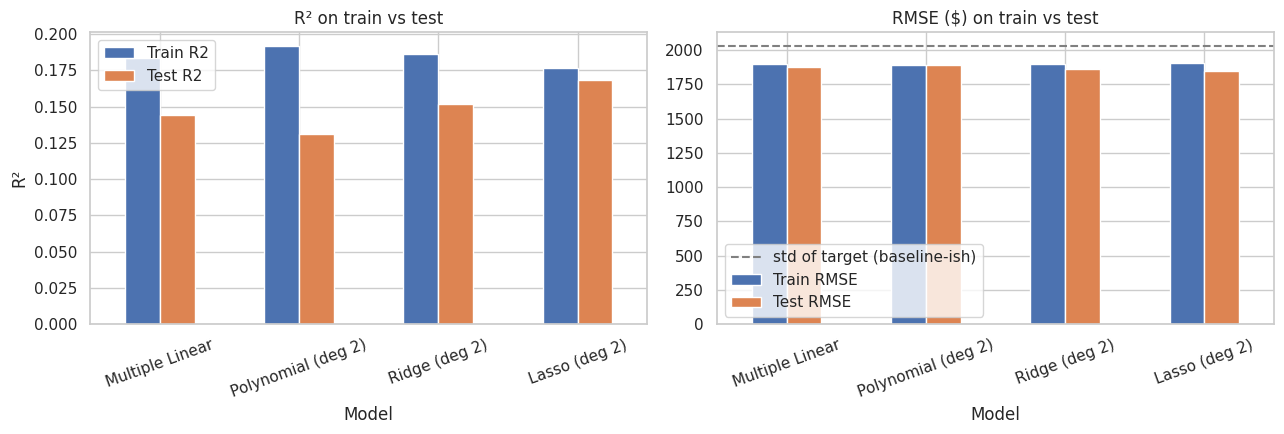

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
results[["Train R2","Test R2"]].plot.bar(ax=ax[0], rot=20)
ax[0].set_title("R² on train vs test"); ax[0].set_ylabel("R²")
results[["Train RMSE","Test RMSE"]].plot.bar(ax=ax[1], rot=20)
ax[1].axhline(y_test.std(), color="gray", ls="--", label="std of target (baseline-ish)")
ax[1].set_title("RMSE ($) on train vs test"); ax[1].legend()
plt.tight_layout(); plt.show()

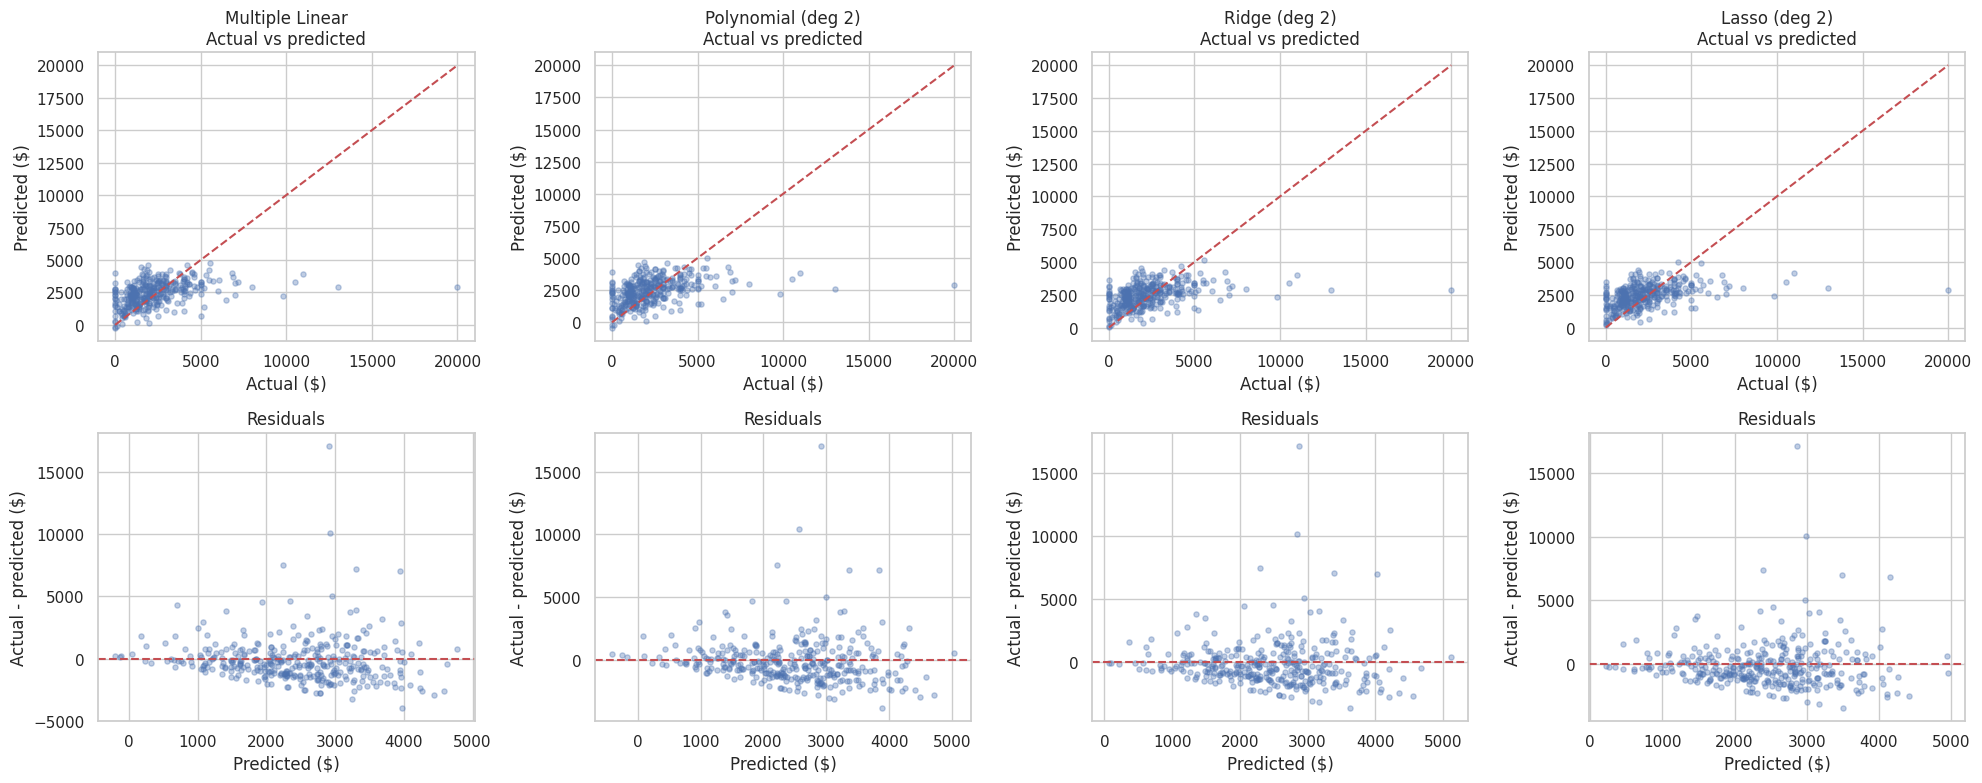

In [16]:
fig, axes = plt.subplots(2, 4, figsize=(20, 8))
for j, (n, m) in enumerate(models.items()):
    pred = m.predict(X_test)
    axes[0, j].scatter(y_test, pred, alpha=0.35, s=14)
    lim = [0, max(y_test.max(), pred.max())]
    axes[0, j].plot(lim, lim, "r--"); axes[0, j].set_title(f"{n}\nActual vs predicted")
    axes[0, j].set_xlabel("Actual ($)"); axes[0, j].set_ylabel("Predicted ($)")
    axes[1, j].scatter(pred, y_test - pred, alpha=0.35, s=14)
    axes[1, j].axhline(0, color="r", ls="--"); axes[1, j].set_title("Residuals")
    axes[1, j].set_xlabel("Predicted ($)"); axes[1, j].set_ylabel("Actual - predicted ($)")
plt.tight_layout(); plt.show()

All four models look pretty similar. The predictions are squeezed into a narrow range even though the actual values go up to \$20,000, and the residuals fan out, with the biggest misses on households that owe a lot. The models get the general trend but can't pick out the households with extreme balances.

### Does added complexity help? A degree sweep

To check this directly, I changed the polynomial degree from 1 to 4 using plain linear regression and compared it to Ridge at the same degrees.

,Linear train R2,Linear test R2,Ridge train R2,Ridge test R2
Degree,,,,
1,0.184,0.144,0.179,0.161
2,0.192,0.131,0.186,0.152
3,0.214,0.118,0.199,0.154
4,0.238,0.057,0.189,0.160


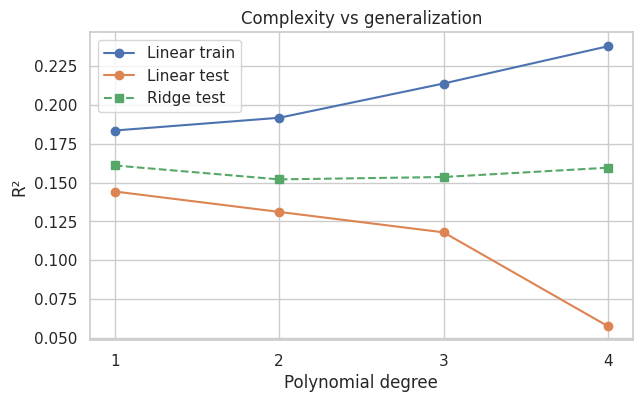

In [17]:
rows = []
for d in [1, 2, 3, 4]:
    lin = Pipeline([("prep", make_preprocessor(d if d > 1 else None)), ("model", LinearRegression())]).fit(X_train, y_train)
    rid = GridSearchCV(Pipeline([("prep", make_preprocessor(d if d > 1 else None)), ("model", Ridge())]),
                       {"model__alpha": np.logspace(-2, 4, 25)}, cv=5,
                       scoring="neg_root_mean_squared_error").fit(X_train, y_train)
    rows.append({"Degree": d,
                 "Linear train R2": lin.score(X_train, y_train), "Linear test R2": lin.score(X_test, y_test),
                 "Ridge train R2": r2_score(y_train, rid.predict(X_train)),  "Ridge test R2": r2_score(y_test, rid.predict(X_test))})
sweep = pd.DataFrame(rows).set_index("Degree")
display(sweep.round(3))

plt.figure(figsize=(7, 4))
plt.plot(sweep.index, sweep["Linear train R2"], "o-", label="Linear train")
plt.plot(sweep.index, sweep["Linear test R2"], "o-", label="Linear test")
plt.plot(sweep.index, sweep["Ridge test R2"], "s--", label="Ridge test")
plt.xticks(sweep.index); plt.xlabel("Polynomial degree"); plt.ylabel("R²"); plt.legend()
plt.title("Complexity vs generalization"); plt.show()

As the degree goes up, training R² keeps climbing (0.18 to 0.24) while test R² drops (0.14 to 0.06). That's a classic sign of overfitting. Ridge stays pretty flat across the degrees (around 0.15 to 0.16). So the extra terms are fitting noise in the training data and not real patterns.

## 8. What did Ridge and Lasso do to the coefficients?

In [18]:
def get_coefs(fitted_gs):
    pipe = fitted_gs.best_estimator_
    names = pipe.named_steps["prep"].get_feature_names_out()
    return pd.Series(pipe.named_steps["model"].coef_, index=names)

poly_pipe = poly_model
poly_coefs = pd.Series(poly_pipe.named_steps["model"].coef_, index=poly_pipe.named_steps["prep"].get_feature_names_out())
ridge_coefs, lasso_coefs = get_coefs(ridge_model), get_coefs(lasso_model)

coef_table = pd.DataFrame({"Polynomial (OLS)": poly_coefs, "Ridge": ridge_coefs, "Lasso": lasso_coefs})
print("Number of features:", len(coef_table))
print("Lasso coefficients set exactly to zero:", int((lasso_coefs == 0).sum()))
print("Largest |coefficient|: OLS = %.0f, Ridge = %.0f, Lasso = %.0f" %
      (poly_coefs.abs().max(), ridge_coefs.abs().max(), lasso_coefs.abs().max()))
print("\nFeatures Lasso kept (nonzero):")
print(lasso_coefs[lasso_coefs != 0].sort_values(key=abs, ascending=False).round(1))

Number of features: 53
Lasso coefficients set exactly to zero: 27
Largest |coefficient|: OLS = 750, Ridge = 572, Lasso = 743

Features Lasso kept (nonzero):
cat__eviction_in_progress_I don't know                     -743.5
num__monthly_rent                                           606.2
cat__intake_quarter_2025-Q1                                 378.3
flags__src_Full-time employment                             289.4
cat__main_reason_behind_on_rent_Lost a job/had hours cut    232.1
cat__employment_status_Employed                             220.4
flags__src_Other                                            163.9
cat__intake_quarter_2025-Q2                                 155.4
cat__intake_quarter_2026-Q1                                 154.8
flags__src_Food benefits - TANF/SNAP                        135.1
num__monthly_household_income^2                            -125.4
cat__has_housing_voucher_Yes                               -116.2
num__adults_in_household monthly_household_income  

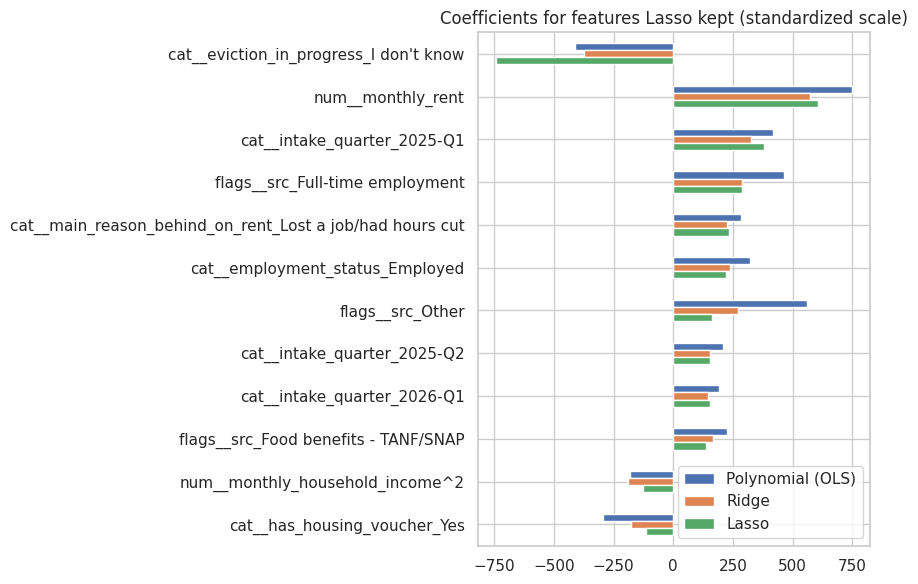

In [19]:
top = lasso_coefs[lasso_coefs != 0].abs().sort_values(ascending=False).head(12).index
coef_table.loc[top].plot.barh(figsize=(9, 6))
plt.title("Coefficients for features Lasso kept (standardized scale)")
plt.gca().invert_yaxis(); plt.tight_layout(); plt.show()

Ridge shrinks all the coefficients a little. Lasso goes further and sets 28 of the 53 features to exactly zero, keeping 25. Of the ones it kept, monthly rent is one of the largest, along with a few categorical answers like intake quarter, full-time employment, and "lost a job/had hours cut" as the reason. The largest coefficient overall is "eviction in progress: I don't know" (negative), which is probably a small, odd group of households, so I wouldn't read too much into it. These coefficients are on the standardized scale and a lot of the features are correlated (like rent and rent²), so they only tell us what's useful for prediction, not what causes what.

## 9. Sensitivity check: how much does `monthly_rent` matter?

Rent looks like the strongest predictor, so I refit the Lasso model without it to see how much it was relying on it.

In [20]:
drop = ["monthly_rent"]
num_nr = [c for c in numeric_features if c not in drop]
prep_nr = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("poly", PolynomialFeatures(degree=2, include_bias=False)),
                      ("scaler", StandardScaler())]), num_nr),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), categorical_features),
    ("flags", "passthrough", flag_features)])
lasso_nr = GridSearchCV(Pipeline([("prep", prep_nr), ("model", Lasso(max_iter=50000))]),
                        {"model__alpha": np.logspace(-1, 3, 25)}, cv=5,
                        scoring="neg_root_mean_squared_error").fit(X_train, y_train)
print(f"Lasso WITH monthly_rent:    Test R2 = {results.loc['Lasso (deg 2)','Test R2']:.3f}")
print(f"Lasso WITHOUT monthly_rent: Test R2 = {r2_score(y_test, lasso_nr.predict(X_test)):.3f}")

Lasso WITH monthly_rent:    Test R2 = 0.168
Lasso WITHOUT monthly_rent: Test R2 = 0.101


## 10. Summary of results

In [21]:
final = results.copy()
final["Gap (Train R2 - Test R2)"] = final["Train R2"] - final["Test R2"]
final.round(3)

,Train R2,Test R2,Train RMSE,Test RMSE,Test MAE,Gap (Train R2 - Test R2)
Model,,,,,,
Multiple Linear,0.184,0.144,1901.187,1872.906,1213.520,0.039
Polynomial (deg 2),0.192,0.131,1891.612,1887.220,1234.906,0.061
Ridge (deg 2),0.186,0.152,1897.967,1864.345,1217.282,0.034
Lasso (deg 2),0.177,0.168,1908.811,1846.285,1204.976,0.009


## 11. Discussion

**Which model did best, and does it matter?**

Lasso did best, with a test R² of about 0.17 and the lowest test RMSE. Ridge came next, then multiple linear regression, then the polynomial model. The differences are small though, so I wouldn't say Lasso is clearly better than the others. All four models explain only about 13% to 17% of the variation in past-due rent. The average error is around \$1,200 when the average amount owed is about \$2,400, so the predictions aren't very accurate.

**Does added complexity help?**

No. The polynomial model had a higher training R², but its test R² went down, and the degree sweep showed the same thing getting worse as more terms were added. Ridge and Lasso made up for some of that by shrinking the less useful features, and Lasso dropped 28 features completely, which made the model simpler. Overall, more features didn't give better predictions.

**How do the models behave?**

They mostly predict within a pretty narrow range, so they struggle with households that owe a very large amount, and the errors get bigger as the predicted amounts go up. Ridge keeps every feature but with smaller weights, while Lasso removes 28 of the 53. That makes Lasso easier to explain since it uses fewer features and doesn't lose much accuracy.

**What does this mean for SLCM?**

- Monthly rent was the most useful feature. That makes sense, since households with higher rent can owe more when they fall behind. When I took it out, Lasso's test R² dropped from about 0.17 to 0.10. Income, household size, employment, voucher status, and the reason for falling behind didn't add as much.
- The models aren't accurate enough to decide who gets help, rank households by need, or set how much assistance a family should get. The predictions can be way off, and that could mean families don't get the help they need.
- The weak results also suggest that the intake form might not capture what really drives arrears. Things like how long a household has been behind, when they first missed a payment, or whether something unexpected happened could matter a lot. If SLCM collected that kind of information, it could help them understand each household better and give more useful support.

**Limitations**

- The data comes from intake forms, so some answers could be wrong or missing, and some people answered "I don't know."
- I only used one 80/20 split, so the numbers could shift a bit with a different split.
- Some `monthly_rent` and `past_due_rent` values are 0. I kept them because I couldn't tell if they were mistakes or real cases, so it might be worth checking with SLCM staff.
- I left out the rarer income sources (Veterans, Pension, and Spousal support) because there weren't enough examples to use them reliably.
- A log transform of the target or a tree-based model might work better, but I didn't try them since they're outside the four techniques for this assignment.
- The models only show relationships between the features and past-due rent. They don't prove that changing any of these would change the amount owed.